In [24]:
import pandas as pd
import numpy as np
import tensorflow as tf

def nasa_loss(y_true, y_pred):
    # Flatten both to 1D so (n, 1) and (n,) can't broadcast into an n x n grid
    y_true = tf.reshape(tf.cast(y_true, tf.float32), [-1])
    y_pred = tf.reshape(tf.cast(y_pred, tf.float32), [-1])

    d = y_pred - y_true  # positive = predicted too late (overestimate)

    penalties = tf.where(
        d < 0,
        tf.exp(-d / 13.0) - 1.0,  # early prediction, milder penalty
        tf.exp(d / 10.0) - 1.0    # late prediction, harsher penalty
    )

    return tf.reduce_mean(penalties) * 100

model = tf.keras.models.load_model(
    'single_lstm_64.keras',
    custom_objects={'nasa_loss': nasa_loss}
)

In [2]:
rul = pd.read_csv('rul.csv')
test = pd.read_csv('test.csv')

In [3]:
rul.shape

(100, 2)

In [4]:
rul.head(10)

,Unnamed: 0,0
0,0,112
1,1,98
2,2,69
3,3,82
4,4,91
5,5,93
6,6,91
7,7,95
8,8,111
9,9,96


In [5]:
rul = rul.rename(columns={'Unnamed: 0' : 'Engine', '0' : 'RUL'})


In [6]:
rul.head(10)

,Engine,RUL
0,0,112
1,1,98
2,2,69
3,3,82
4,4,91
5,5,93
6,6,91
7,7,95
8,8,111
9,9,96


In [7]:
test.head(10)

,Unnamed: 0,engine,cycle,2,3,4,6,7,8,11,12,13,15,16,17,18,19,21,24,25
0,0,1,1,1.053128,1.018616,0.0,0.687388,-0.854380,-1.190038,0.600342,-0.796358,-0.672100,-1.278278,0.412159,-0.918519,-0.937290,-0.981826,-0.779529,0.233911,0.773017
1,1,1,2,-1.229360,-1.031739,0.0,-1.942557,-0.335090,-1.501236,1.682661,-1.221017,-0.484537,-0.149293,1.010825,-0.500147,-0.218938,-1.645703,-0.132811,1.123458,0.941543
2,2,1,3,0.140133,0.335164,0.0,-0.436864,-0.583232,-0.840916,0.839592,-0.654805,-0.372441,-0.149293,0.752310,-0.918519,-0.704987,0.055314,-0.132811,1.457037,1.174313
3,3,1,4,1.920474,-0.006562,0.0,-0.477015,-1.046649,-0.274289,0.794020,-0.937911,-0.887465,-0.977215,-0.050446,-0.639604,-0.562032,-1.341760,-1.426246,1.012264,0.774879
4,4,1,5,0.642281,-0.006562,0.0,-0.336484,-0.542149,-0.776222,0.896556,-1.221017,-0.920123,-0.864317,0.997219,-0.918519,-0.733578,-1.037816,-2.072963,0.956668,1.140794
5,5,1,6,0.550981,1.018616,0.0,-1.139521,-1.868312,-1.533583,0.964913,-1.362569,-0.637235,-1.052481,0.684280,-0.221232,-0.839774,-0.485919,-0.779529,0.511895,0.523487
6,6,1,7,0.003184,0.676890,0.0,-1.139521,-1.174829,-0.450523,0.588949,-0.654805,-0.618258,-0.864317,0.806734,-0.500147,-0.456347,-1.349758,-1.426246,0.178315,0.975062
7,7,1,8,0.277082,-0.006562,0.0,-0.276256,-1.577443,-0.891109,0.247165,-0.654805,-0.553384,-1.240645,0.915582,-0.500147,-0.917889,-0.552573,-0.132811,1.290247,0.297234
8,8,1,9,-1.640208,-0.006562,0.0,-1.601267,0.460279,0.379339,1.272519,-0.513252,-0.743594,-0.638520,0.833946,-0.639604,-0.498212,-0.179309,-1.426246,1.568231,1.504847
9,9,1,10,-1.138061,-0.348288,0.0,-1.219824,-0.860954,-1.142075,1.033270,-0.796358,-0.593544,-1.504075,0.793128,-0.500147,-0.501786,-0.872513,-1.426246,0.289508,0.852159


In [8]:
feature_cols = [2, 3, 4, 6, 7, 8, 11, 12, 13, 15, 16, 17, 18, 19, 21, 24, 25]
feature_cols = [str(index) for index in feature_cols]

In [9]:
def create_windows(df, feature_cols, window_length=30):

    X, y = [], []

    for engine_id, engine_df in df.groupby('engine'):

        engine_df = engine_df.sort_values('cycle')
        last_cycle = len(engine_df) - 1

        features = engine_df[feature_cols].to_numpy()

        if 'rul' in engine_df.columns:
            rul = engine_df['rul'].to_numpy()

        X.append(features[-window_length:])
        # X.append(features)



    return np.array(X), np.array(y)

In [10]:
indices = test.groupby('engine')['cycle'].idxmax().to_numpy()
print(indices)

[   30    79   205   311   409   514   674   840   895  1087  1170  1387
  1582  1628  1704  1817  1982  2115  2250  2434  2582  2621  2751  2937
  2985  3061  3201  3359  3530  3673  3869  4014  4064  4267  4465  4591
  4712  4837  4874  5007  5130  5286  5458  5512  5664  5810  5883  5961
  6264  6338  6482  6671  6835  6956  7069  7205  7365  7541  7635  7782
  7941  8173  8328  8496  8567  8714  8785  8972  9026  9178  9246  9377
  9489  9626  9714  9919 10081 10153 10254 10387 10600 10762 10835 11007
 11041 11151 11207 11275 11452 11598 11832 11982 12226 12359 12448 12545
 12679 12800 12897 13095]


In [11]:
X_test, _ = create_windows(test, feature_cols, window_length=30)

In [12]:
X_test

array([[[-1.22936009, -1.03173912,  0.        , ..., -0.13281117,
          1.12345759,  0.94154261],
        [ 0.14013303,  0.33516407,  0.        , ..., -0.13281117,
          1.4570374 ,  1.17431297],
        [ 1.92047408, -0.00656173,  0.        , ..., -1.42624592,
          1.01226431,  0.77487903],
        ...,
        [ 0.6422805 ,  0.33516407,  0.        , ..., -0.77952854,
          1.12345759,  0.66687358],
        [-1.13806055,  1.36034145,  0.        , ..., -1.42624592,
          1.51263404,  1.08399807],
        [-0.27071491,  1.36034145,  0.        , ..., -0.13281117,
         -0.04407177,  0.60262896]],

       [[ 1.78352477,  1.36034145,  0.        , ..., -0.13281117,
         -0.26645832, -0.38152413],
        [-1.73150757, -1.03173912,  0.        , ...,  0.5139062 ,
          0.40070132,  0.86705609],
        [ 0.23143257,  1.01861566,  0.        , ..., -0.13281117,
          0.34510468, -0.40014576],
        ...,
        [-1.32065963, -1.37346491,  0.        , ..., -

In [13]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score


y_test = rul['RUL'].to_numpy()
y_test = np.clip(y_test, a_min=0, a_max=125)

predictions = model.predict(X_test).flatten()

print(predictions, len(predictions))


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
[106.38517  114.67857   48.991436  81.49451   95.41531   94.188675
  93.10148   90.07682  114.20053   89.26865   72.26909   95.74989
  83.0551   103.77108   98.83455   99.00554   41.433422  36.556026
  88.53896   14.920603  72.909096 115.928925 115.04046   24.483114
  96.01625  107.50847   93.026886 105.9016    95.99988   83.02255
  10.270587  50.10927   92.17673    9.752563  10.841547  18.093695
  31.889456  43.578995 116.13196   22.490965  32.757187  15.640239
  54.846565 108.32979   90.00877   30.641754 106.79561   96.982285
  16.883503  90.33151  107.72991   30.59804   29.483973 112.606285
 108.85593   13.02658  102.74515   40.275963 105.456894 102.776855
  23.57393   43.00784   71.80782   24.46152  117.28105   14.779937
 110.41452   12.704899 111.984856  97.526535 105.49003   63.096916
  97.73169  100.76212  103.44823    9.006157  27.900078 121.11942
 110.93077   87.341644   8.345749  13.695614 115.544464  63.24962
 114.71652  110.871315 106.4

In [14]:
print(f'RMSE: {root_mean_squared_error(y_test, predictions):.3f}')
print(f'MAE: {mean_absolute_error(y_test, predictions):.3f}')
print(f'R^2: {r2_score(y_test, predictions):.3f}')
print(f'NASA Score: {nasa_loss(np.array(y_test), predictions) * 100:.2f}')

RMSE: 14.115
MAE: 10.169
R^2: 0.876
NASA Score: 363.48


Share Positive: 55%
Median Residual: 0.8 cycles


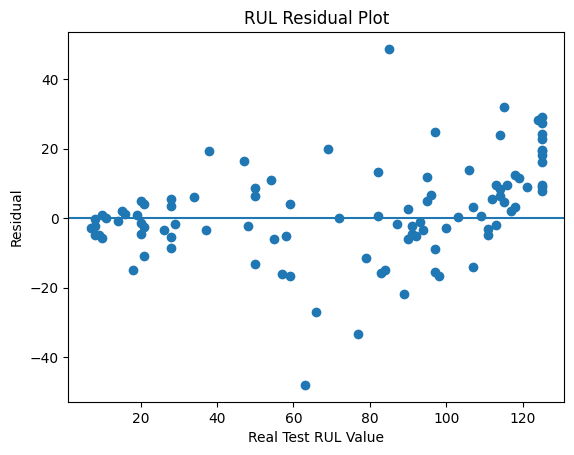

In [15]:
import matplotlib.pyplot as plt

m, b = np.polyfit(y_test, predictions, 1)

residuals = y_test - predictions
x = np.arange(0, max(y_test), 1)
plt.scatter(y_test, residuals)
plt.axhline(y=0)
plt.xlabel('Real Test RUL Value')
plt.ylabel('Residual')
plt.title('RUL Residual Plot')

print(f'Share Positive: {np.mean(residuals > 0):.0%}')
print(f'Median Residual: {np.median(residuals):.1f} cycles')

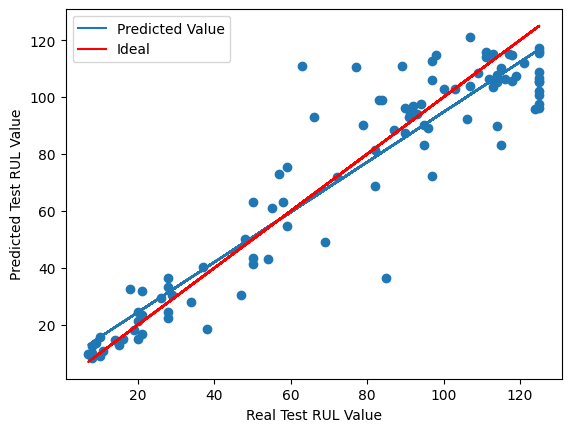

In [16]:
plt.scatter(y_test, predictions)
plt.plot(y_test, m * y_test + b, label='Predicted Value')
plt.plot(y_test, y_test, color='red', label='Ideal')
plt.xlabel('Real Test RUL Value')
plt.ylabel('Predicted Test RUL Value')
plt.legend()
# 

In [25]:
predictions = model.predict(X_test)
predictions = predictions
print(np.mean(predictions < y_test))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
0.5265


In [26]:
print(nasa_loss(predictions, y_test))

tf.Tensor(409.71307, shape=(), dtype=float32)
